The purpose of this notebook to create the insertion pipeline
The tool receives the multiple views of general object and a prompt to generate new object

imports

In [37]:
from pathlib import Path
import os
from ObjaverseDataset import ObjaverseDataset
from torch.utils.data import DataLoader
from pathlib import Path

from prompts import *
from utils import _convert_trimesh_to_o3d

# Keep relative input and output paths anchored at the project root.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()
if not (PROJECT_ROOT / "utils.py").is_file():
    raise RuntimeError(f"Open this notebook from the project root or experiments/: {Path.cwd()}")
os.chdir(PROJECT_ROOT)

from utils import *

### 0. Ojbect preparation

In [38]:
objaverse_dataset = ObjaverseDataset(category="duck", limit=1)
objaverse_dataloader = DataLoader(objaverse_dataset, batch_size=1, shuffle=False, collate_fn=objaverse_dataset.collate_fn)

dict_keys(['Band_Aid', 'Bible', 'CD_player', 'Christmas_tree', 'Dixie_cup', 'Ferris_wheel', 'Lego', 'Rollerblade', 'Sharpie', 'Tabasco_sauce', 'aerosol_can', 'air_conditioner', 'airplane', 'alarm_clock', 'alcohol', 'alligator', 'almond', 'ambulance', 'amplifier', 'anklet', 'antenna', 'apple', 'apricot', 'apron', 'aquarium', 'arctic_(type_of_shoe)', 'armband', 'armchair', 'armoire', 'armor', 'army_tank', 'artichoke', 'ashtray', 'asparagus', 'atomizer', 'automatic_washer', 'avocado', 'award', 'awning', 'ax', 'baboon', 'baby_buggy', 'backpack', 'bagel', 'baguet', 'bait', 'ball', 'ballet_skirt', 'balloon', 'bamboo', 'banana', 'bandage', 'bandanna', 'banjo', 'banner', 'barbell', 'barge', 'barrel', 'barrow', 'baseball', 'baseball_bat', 'baseball_cap', 'baseball_glove', 'basket', 'basketball', 'basketball_backboard', 'bass_horn', 'bat_(animal)', 'bath_mat', 'bath_towel', 'bathrobe', 'bathtub', 'battery', 'beachball', 'bead', 'beanbag', 'beanie', 'bear', 'bed', 'bedpan', 'bedspread', 'beef_(fo

In [39]:
current_object = objaverse_dataset[0] # obj_path, vertices, faces
mesh = current_object["mesh"]
mesh.show()

=== Processing UID: b5c9d06f19be4c92a1708515f6655573 ===
FEngine (64 bits) created at 0x37c80ee00 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feature level: 1


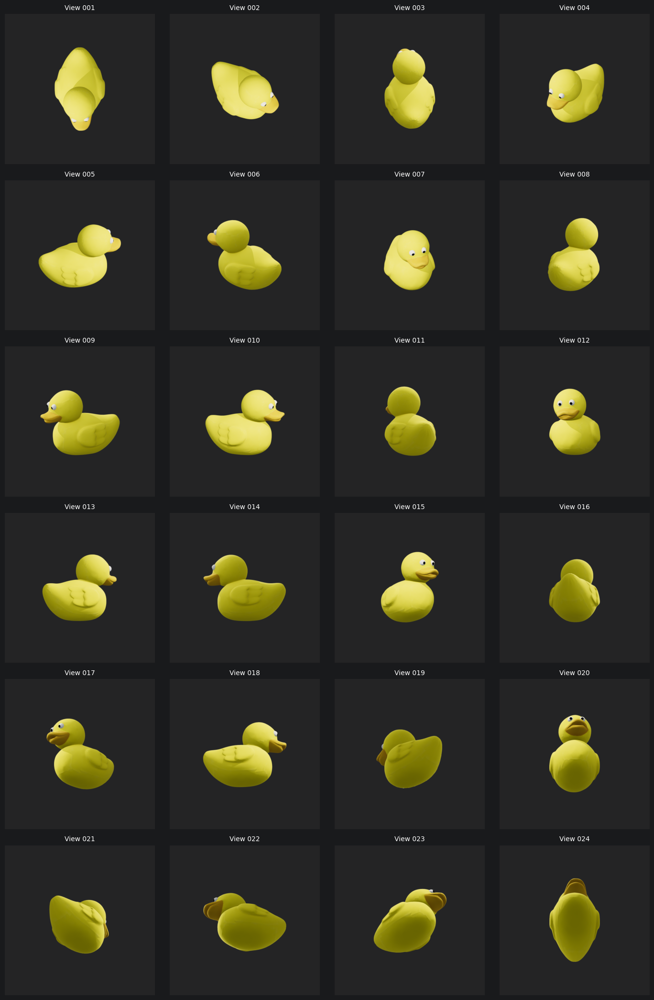

In [40]:
uid_value = current_object["uid"]
uid = uid_value[0] if isinstance(uid_value, (list, tuple)) else uid_value
print(f"=== Processing UID: {uid} ===")
mesh = current_object["mesh"][0] if isinstance(current_object["mesh"], list) else current_object["mesh"]
output_dir = f"rendered_views/{uid}"
rendered_info = render_n_views(mesh, n_views=24, output_dir=output_dir, frame_scale=1.8)
show_rendered_grid(output_dir)

#### 0.1) Input.
Now, the tool should receive the prompt which object should be generated

In [149]:
# prompt = "left bunny ear"
prompt = "car wheel" # what should be generated
directions = ["left"] # where should it be put
rendered_info = rendered_info # all views
image_path = f"generated_images/Flux2_dev_00012_.png" # path of image for 3d object (used for naming)
new_object_mesh_path = "generated_models/ComfyUI_00032.glb" # path to 3d object

Now the 3d object for the prompt should be generated

In [42]:
# image_path = generate_image_from_text(prompt)
# new_object_mesh_path = generate_3d_object_from_image(image_path)
# new_object_mesh = trimesh.load(new_object_mesh_path)



In [43]:
# new_object_mesh.show()

### 1) Now, render new object from 6 views to give agent a better understanding about the structure of new object

FEngine (64 bits) created at 0x12244c000 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feature level: 1


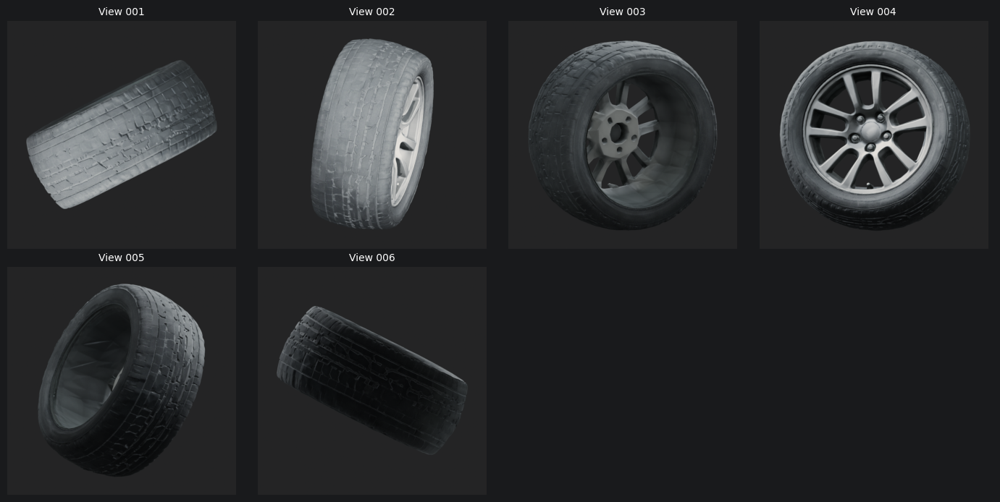

In [87]:
output_dir = f"rendered_new_object_views/{Path(image_path).stem}"
new_object_mesh = trimesh.load("generated_models/ComfyUI_00032.glb")
rendered_new_object_info = render_n_views(new_object_mesh, n_views=6, output_dir=output_dir, is_objaverse_model=False)
show_rendered_grid(output_dir)

### 2) Figure out the center of figure and give each view a direction (left, up, left-up, etc.

We have to give each view a direction from: front, left, right, back, up, down, back-right-up, front-left-down, front-up-left, etc

Since objects may not be aligned in the way that the model will always be rendered from forward, but may be rotated, we ask a VLM to choose from all view the view which the most fits "forward" view. From this based on eyes we can give direction to all other views

In [66]:
FRONT_VIEW_SELECTION_SYSTEM_PROMPT = """
You are a visual reasoning model for 3D object editing.

The input image contains numbered views of the
same 3D object from different camera positions.

Identify the view that most directly shows
the object's intrinsic front side.

The object may have an arbitrary 3D orientation.
Do not assume that it is standing upright.

Compare all views and identify characteristic
features that indicate the object's front.

Return a JSON object with the following fields:
- reasoning: a brief explanation of your selection.
- front_view: the integer ID of the selected view.
"""

In [56]:
from PIL import ImageDraw
def create_views_grid(rendered_info, cols=6, size=320):
    """
    Create a numbered grid of rendered views. So that model has access to all views at the same time
    """

    rows = math.ceil(len(rendered_info) / cols)

    grid = Image.new(
        "RGB",
        (cols * size, rows * (size + 30)),
        (35, 35, 35)
    )

    draw = ImageDraw.Draw(grid)

    for i, (_, path) in enumerate(rendered_info):
        image = Image.open(path).convert("RGB")
        image = image.resize((size, size))

        x = (i % cols) * size
        y = (i // cols) * (size + 30)

        grid.paste(image, (x, y + 30))
        draw.text(
            (x + 10, y + 8),
            f"View {i + 1:03d}",
            fill="white"
        )

    return grid

In [152]:
def estimate_object_orientation(
    mesh,
    rendered_info,
    grid_path,
    ollama_host,
    model_name="qwen3-vl:8b-instruct"
):
    """Estimate object-centric coordinate axes."""

    client = ollama.Client(host=ollama_host)

    response = client.chat(
        model=model_name,
        messages=[
            {
                "role": "system",
                "content": FRONT_VIEW_SELECTION_SYSTEM_PROMPT
            },
            {
                "role": "user",
                "content": "Identify the most frontal view.",
                "images": [str(grid_path)]
            }
        ],
        format="json",
        options={
            "temperature": 0.05,
            "num_ctx": 16384
        }
    )

    result = json.loads(response["message"]["content"])
    print("VLM response:", result)

    front_idx = int(result["front_view"]) - 1

    # display(Image.open(rendered_info[front_idx][1]))

    if not 0 <= front_idx < len(rendered_info):
        raise ValueError("Invalid front view index")

    # Use the same mesh center as the renderer
    mesh_o3d = _convert_trimesh_to_o3d(mesh)
    center = mesh_o3d.get_axis_aligned_bounding_box().get_center()

    eye_pos, _ = rendered_info[front_idx]

    # Assume Y-up orientation
    up = np.array([0., 1., 0.])

    # Project front direction onto the horizontal plane
    front = np.asarray(eye_pos) - center
    front -= np.dot(front, up) * up

    if np.linalg.norm(front) < 1e-8:
        raise ValueError("Invalid frontal camera direction")

    front /= np.linalg.norm(front)

    # Compute anatomical directions
    left = np.cross(up, front)
    left /= np.linalg.norm(left)

    return {
        "center": center,
        "front_view_idx": front_idx,
        "front": front,
        "back": -front,
        "left": left,
        "right": -left,
        "up": up,
        "down": -up
    }

In [99]:
def classify_views(rendered_info, orientation, threshold=0.35):
    """
    Classify camera views using object-centric axes. No VLM is used
    Example output:
    {
    "index": 8,
    "eye_pos": array([1.8, 0.9, 1.2]),
    "path": "rendered_views/view_009.png",
    "labels": ["front", "left", "up"],
    "scores": {
        "front": 0.51,
        "back": -0.51,
        "left": 0.77,
        "right": -0.77,
        "up": 0.38,
        "down": -0.38
    }
}
    """

    directions = [
        "front", "back",
        "left", "right",
        "up", "down"
    ]

    center = orientation["center"]
    classified_views = []

    for i, (eye_pos, path) in enumerate(rendered_info):

        camera_dir = np.asarray(eye_pos) - center
        camera_dir /= np.linalg.norm(camera_dir)
        # scores of each direction are decided by dot product with orientation vector
        scores = {
            name: float(np.dot(camera_dir, orientation[name]))
            for name in directions
        }

        labels = [
            name for name in directions
            if scores[name] >= threshold
        ]

        classified_views.append({
            "index": i,
            "eye_pos": eye_pos,
            "path": path,
            "labels": labels,
            "scores": scores
        })

    return classified_views

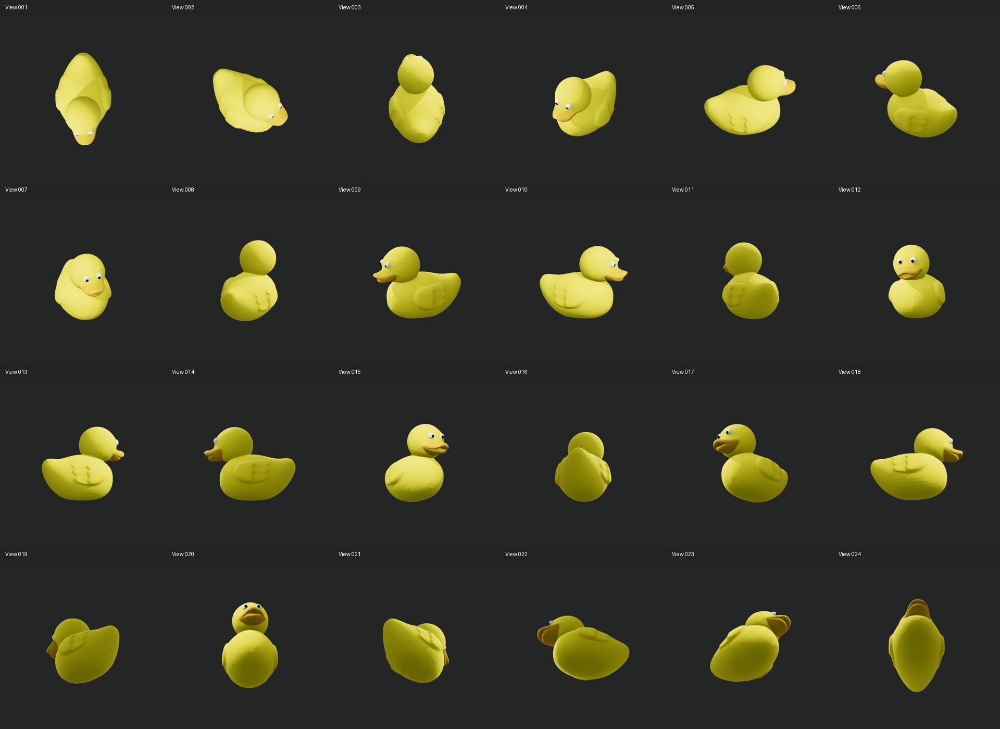

In [150]:
views_grid = create_views_grid(rendered_info)
views_grid.save("views_grid.png")

display(views_grid)

VLM response: {'reasoning': "The most frontal view is the one where the duck's face is directly facing the camera, showing its eyes and beak clearly. View015 is the most frontal view because it shows the duck's face directly towards the viewer, with the beak and eyes centered in the frame, indicating the front side of the object.", 'front_view': 15}
Front view: 15


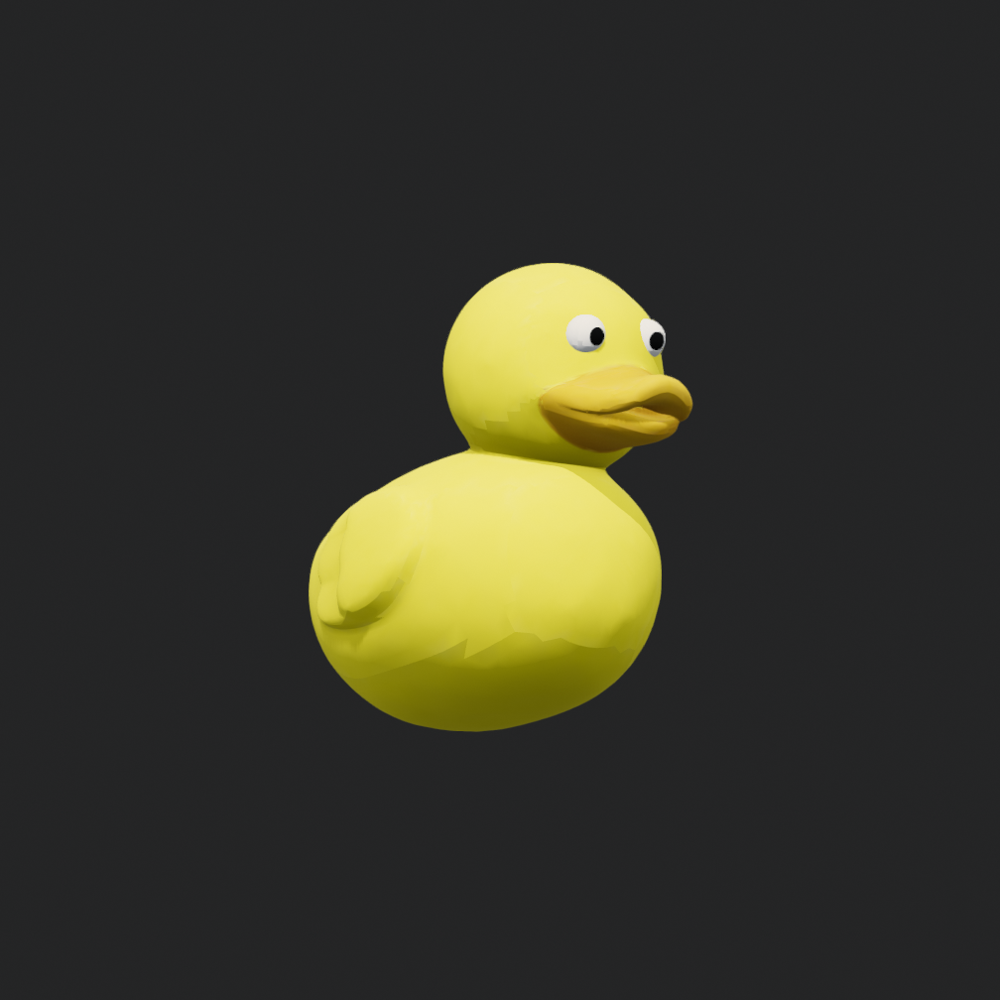

In [153]:
orientation = estimate_object_orientation(
    mesh,
    rendered_info,
    grid_path="views_grid.png",
    ollama_host="192.168.178.23"
)

front_idx = orientation["front_view_idx"]

print(f"Front view: {front_idx + 1}")

display(Image.open(rendered_info[front_idx][1]))

In [154]:
classified_views = classify_views(
    rendered_info,
    orientation
)

for view in classified_views:
    print(
        f"View {view['index'] + 1:03d}: "
        f"{'-'.join(view['labels'])}"
    )

View 001: up
View 002: front-up
View 003: back-up
View 004: left-up
View 005: right-up
View 006: back-up
View 007: front-up
View 008: back-right-up
View 009: left
View 010: front-right
View 011: back
View 012: front-left
View 013: right
View 014: back-left
View 015: front
View 016: back-right
View 017: left-down
View 018: front-right-down
View 019: back-down
View 020: front-left-down
View 021: right-down
View 022: left-down
View 023: front-down
View 024: down


### 3) Select only relevant views for atachment point

In [89]:
def select_relevant_views(
    classified_views,
    directions,
    threshold=0.35,
    max_views=6
):
    """
    Select and rank views matching all requested directions.
    Selection is based on scores for each direction and not labels
    """

    relevant_views = []

    for view in classified_views:
        scores = [
            view["scores"][direction]
            for direction in directions
        ]

        # Check all spatial constraints
        if all(score >= threshold for score in scores):

            relevance = np.mean(scores)

            relevant_views.append(
                (view["index"], relevance)
            )

    # Sort views by relevance
    relevant_views.sort(
        key=lambda item: item[1],
        reverse=True
    )

    return [
        index for index, score
        in relevant_views[:max_views]
    ]

In [155]:
selected_views = select_relevant_views(
    classified_views,
    directions=directions,
    threshold=0.3
)

print("Selected views:")

for i in selected_views:
    print(
        f"View {i + 1:03d}: "
        f"{'-'.join(classified_views[i]['labels'])}"
    )

Selected views:
View 009: left
View 017: left-down
View 012: front-left
View 014: back-left
View 004: left-up
View 022: left-down


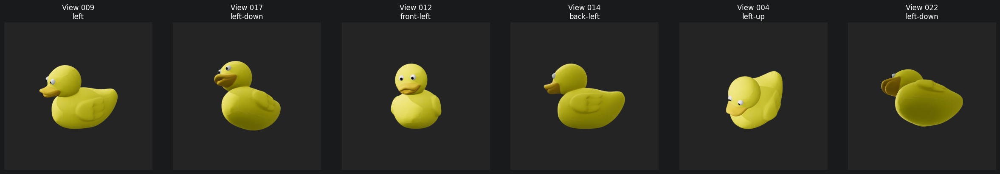

In [156]:
if selected_views:
    fig, axes = plt.subplots(
        1,
        len(selected_views),
        figsize=(4 * len(selected_views), 4),
        squeeze=False
    )

    for ax, i in zip(axes.flat, selected_views):
        view = classified_views[i]

        ax.imshow(Image.open(view["path"]))
        ax.set_title(
            f"View {i + 1:03d}\n"
            f"{'-'.join(view['labels'])}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No relevant views found")

### 4) Generate the attachment point

In [145]:

ATTACHMENT_POINT_SYSTEM_PROMPT = """
You are a visual reasoning model for 3D object editing.

Image 1 shows the original object.
The remaining images show the component to attach.

Imagine the component attached to the original object
according to the user's instructions.

Predict the single point on the original object's
surface where the new component should connect.

The point represents the center of the contact area
between the two objects.

Return coordinates relative to Image 1 only.
Use integer coordinates normalized to [0, 1000].

Return a JSON object with the following fields:
- is_found: boolean
- point_2d: [x, y] or null if not found
"""
def generate_attachment_point(
    ollama_host,
    image_path,
    user_prompt,
    rendered_new_object_info,
    model_name="qwen3-vl:8b-instruct"
):
    """Predict a surface attachment point."""
    reference_images = [element[1] for element in rendered_new_object_info]
    with Image.open(image_path) as image:
        width, height = image.size

    client = ollama.Client(host=ollama_host)

    response = client.chat(
        model=model_name,
        messages=[
            {
                "role": "system",
                "content": ATTACHMENT_POINT_SYSTEM_PROMPT
            },
            {
                "role": "user",
                "content": user_prompt,
                "images": [
                    str(image_path),
                    *[str(path) for path in reference_images]
                ]
            }
        ],
        format="json",
        options={
            "temperature": 0.1,
            "num_ctx": 16384,
            "num_predict": 256
        }
    )

    result = json.loads(response["message"]["content"])

    if not result["is_found"]:
        return None

    x, y = result["point_2d"]

    return (
        round(x / 1000 * (width - 1)),
        round(y / 1000 * (height - 1))
    )


In [117]:
def pixel_to_3d(
    mesh,
    point_2d,
    eye_pos,
    width=1008,
    height=1008,
    frame_scale=1.8
):
    """
    Project a 2D pixel onto the mesh surface using raycasting.
    """

    # Use the same geometry as in render_n_views
    mesh_o3d = _convert_trimesh_to_o3d(mesh)

    bbox = mesh_o3d.get_axis_aligned_bounding_box()
    center = bbox.get_center()
    extent = bbox.get_max_extent()

    half_size = extent / 2 * frame_scale
    aspect = width / height

    # Camera coordinate system
    z_cam = eye_pos - center
    z_cam /= np.linalg.norm(z_cam)

    if abs(z_cam[1]) > 0.99:
        up = np.array([0, 0, -1 if z_cam[1] > 0 else 1])
    else:
        up = np.array([0, 1, 0])

    x_cam = np.cross(up, z_cam)
    x_cam /= np.linalg.norm(x_cam)
    y_cam = np.cross(z_cam, x_cam)

    # Convert pixel coordinates to orthographic coordinates
    px, py = point_2d

    x = (2 * (px + 0.5) / width - 1) * half_size * aspect
    y = (1 - 2 * (py + 0.5) / height) * half_size

    # Construct an orthographic ray
    origin = eye_pos + x * x_cam + y * y_cam
    direction = -z_cam

    ray_mesh = o3d.t.geometry.TriangleMesh.from_legacy(mesh_o3d)

    scene = o3d.t.geometry.RaycastingScene()
    scene.add_triangles(ray_mesh)

    ray = np.concatenate([origin, direction])
    rays = o3d.core.Tensor([ray], dtype=o3d.core.Dtype.Float32)

    hits = scene.cast_rays(rays)

    t_hit = hits["t_hit"].numpy()[0]

    if not np.isfinite(t_hit):
        return None, None

    anchor_point = origin + t_hit * direction
    anchor_normal = hits["primitive_normals"].numpy()[0]

    return anchor_point, anchor_normal


In [130]:
def validate_anchor_point(
    point,
    orientation,
    directions
):
    """
    Check whether a point satisfies spatial constraints.
    """

    relative_point = point - orientation["center"]

    return all(
        np.dot(relative_point, orientation[d]) >= 0
        for d in directions
    )


View 9
2D point: (453, 604)


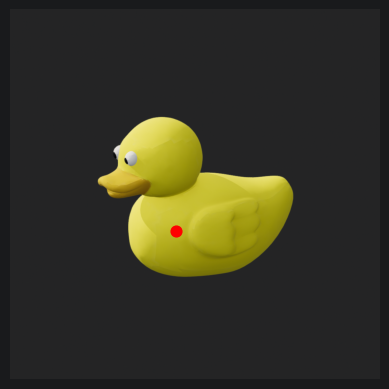

3D point: [ 0.22199581 -0.02886485  0.17346535]

View 17
2D point: (450, 581)


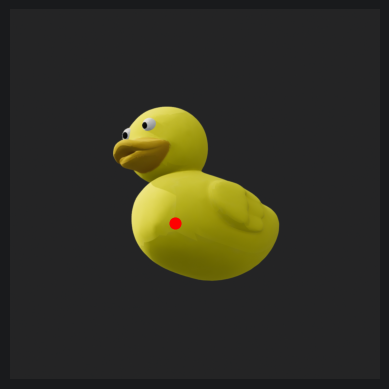

3D point: [ 0.14777212 -0.19268595  0.24554958]

View 12
2D point: (478, 629)


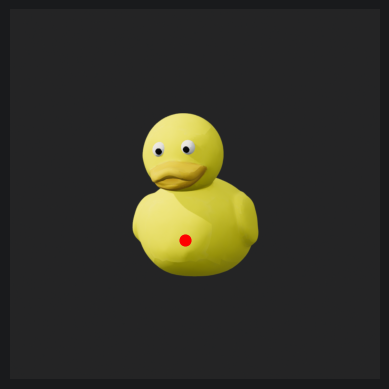

3D point: [ 0.05347255 -0.13659019  0.31711109]

View 14
2D point: (453, 554)


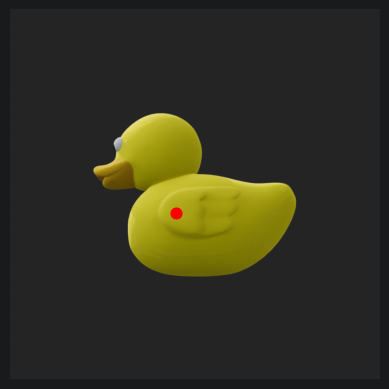

3D point: [ 0.29639191 -0.05444685  0.02395502]

View 4
2D point: (478, 680)


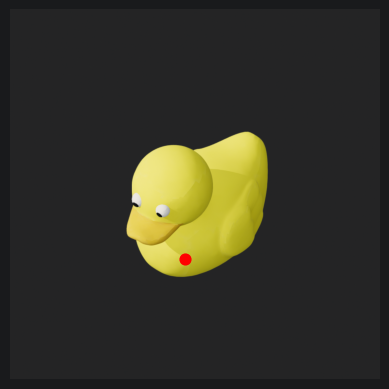

3D point: [ 0.15266489 -0.05489903  0.26971949]

View 22
2D point: (435, 624)


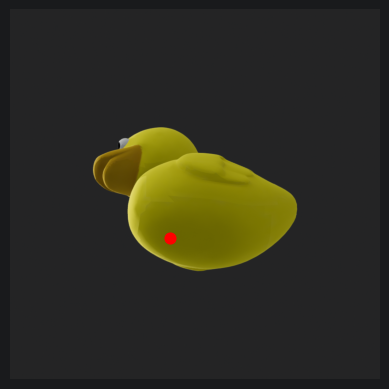

3D point: [-0.00933183 -0.31742281  0.11871266]
Valid points: 6/24


In [157]:
#TODO: replace hardcoded enhanced prompt with llm request
enhanced_prompt = """
Locate the attachment point for a car wheel
below the visible wing, slightly toward the chest,
on the lower body of the duck.
"""
# we should enhance the prompt via other LLM for better performance

N_BASE_VIEWS = 24
N_PART_VIEWS = 6
FRAME_SCALE = 1.8
OLLAMA_HOST = "192.168.178.23"

anchor_points = []
anchor_normals = []

for i in selected_views:
    eye_pos, view_path = rendered_info[i]

    point_2d = generate_attachment_point(
        ollama_host="192.168.178.23",
        image_path=view_path,
        rendered_new_object_info = rendered_new_object_info,
        user_prompt=enhanced_prompt
    )

    print(f"\nView {i + 1}")
    print("2D point:", point_2d)

    if point_2d is None:
        print("VLM rejected this view")
        continue

    plt.imshow(Image.open(view_path))
    plt.scatter(*point_2d, c="red", s=60)
    plt.axis("off")
    plt.show()

    point_3d, normal = pixel_to_3d(
        mesh,
        point_2d,
        eye_pos,
        frame_scale=1.8
    )

    # if not validate_anchor_point(
    #     point_3d,
    #     orientation,
    #     directions
    # ):
    #     print("Point violates spatial constraints")
    #     continue

    if point_3d is None:
        print("Raycasting missed the mesh")
        continue

    print("3D point:", point_3d)

    anchor_points.append(point_3d)
    anchor_normals.append(normal)

    # plt.imshow(Image.open(view_path))
    # plt.scatter(*point_2d, c="red", s=60)
    # plt.axis("off")
    # plt.show()

anchor_points = np.asarray(anchor_points)
anchor_normals = np.asarray(anchor_normals)

print(f"Valid points: {len(anchor_points)}/{len(rendered_info)}")

In [158]:
scene = trimesh.Scene([mesh])

for point in anchor_points:
    sphere = trimesh.creation.icosphere(
        radius=mesh.extents.max() * 0.015
    )

    sphere.apply_translation(point)
    sphere.visual.face_colors = [255, 0, 0, 255]

    scene.add_geometry(sphere)

scene.show()

In [159]:
from sklearn.cluster import DBSCAN

if len(anchor_points) < 1:
    raise ValueError("Not enough valid anchor points")

labels = DBSCAN(
    eps=mesh.extents.max() * 0.2,
    min_samples=3
).fit_predict(anchor_points)

valid_labels = labels[labels != -1]

if len(valid_labels) == 0:
    raise ValueError("No consistent attachment region found")

best_label = np.bincount(valid_labels).argmax()
indices = np.where(labels == best_label)[0]

cluster_points = anchor_points[indices]
center = cluster_points.mean(axis=0)

# Select the closest actual surface point
best_idx = indices[
    np.argmin(np.linalg.norm(cluster_points - center, axis=1))
]

anchor_point = anchor_points[best_idx]
anchor_normal = anchor_normals[best_idx]

In [161]:
if anchor_point is not None:
    sphere = trimesh.creation.icosphere(
        subdivisions=3,
        radius=mesh.extents.max() * 0.025
    )

    sphere.apply_translation(anchor_point)
    sphere.visual.face_colors = [255, 0, 0, 255]

    scene = trimesh.Scene([mesh, sphere])
    scene.show()

In [54]:
scene.show()